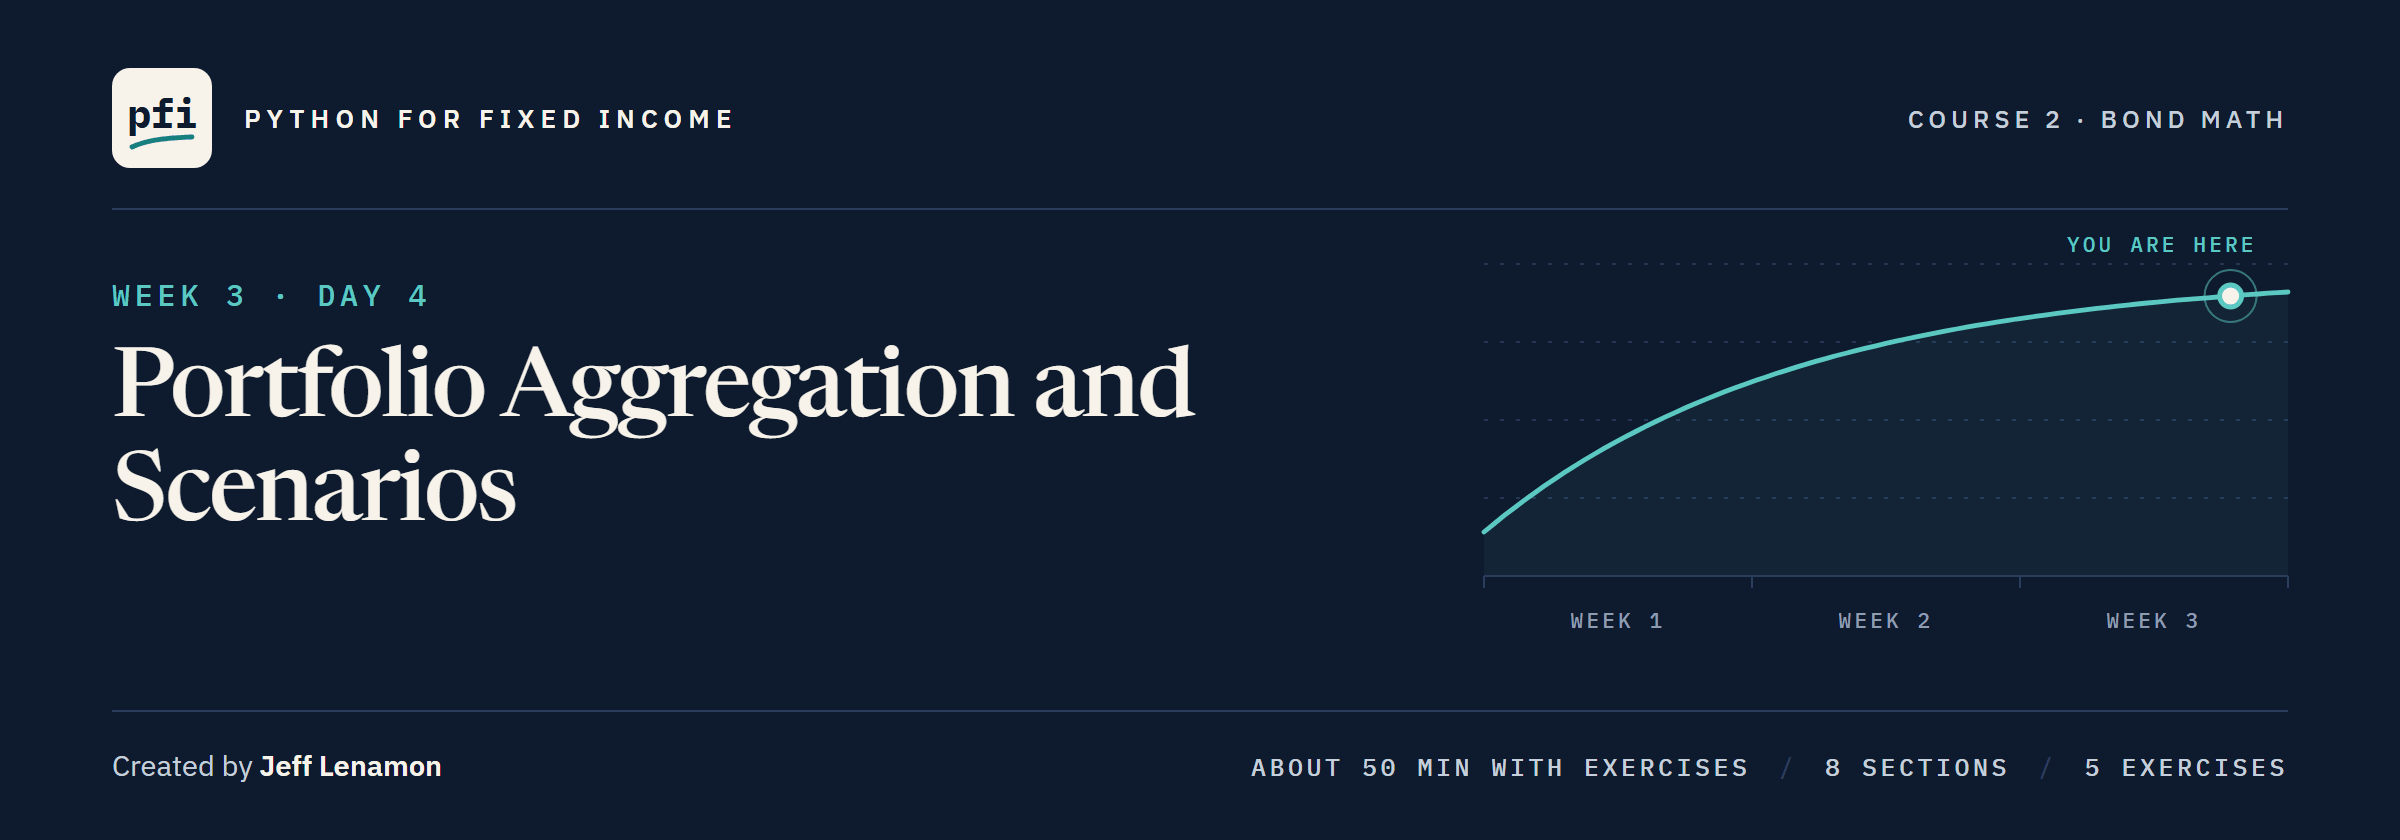

# Portfolio Aggregation and Scenarios

Week 3, Day 4. The 200 bonds rolled into one book, its risk card, and the book repriced in full under rate and spread what-ifs.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day4/14_portfolio_aggregation_and_scenarios.ipynb)

### The Desk Lead's Note

> The September book, 200 positions. I want the risk report's top lines from your own tested functions: value, duration, spread, DTS, convexity, DV01. Then the what-ifs, repriced in full: every yield -100, -25, +25 and +100 bp; every spread +25 bp and +10 percent. How far off is the duration-and-convexity shortcut? Which sectors carry each loss? Send me the grid as a workbook.

The issuers are invented; every scenario is a what-if, never a forecast.

**First a function that weights the book the way Excel does.**

## Your Route Through Day 4

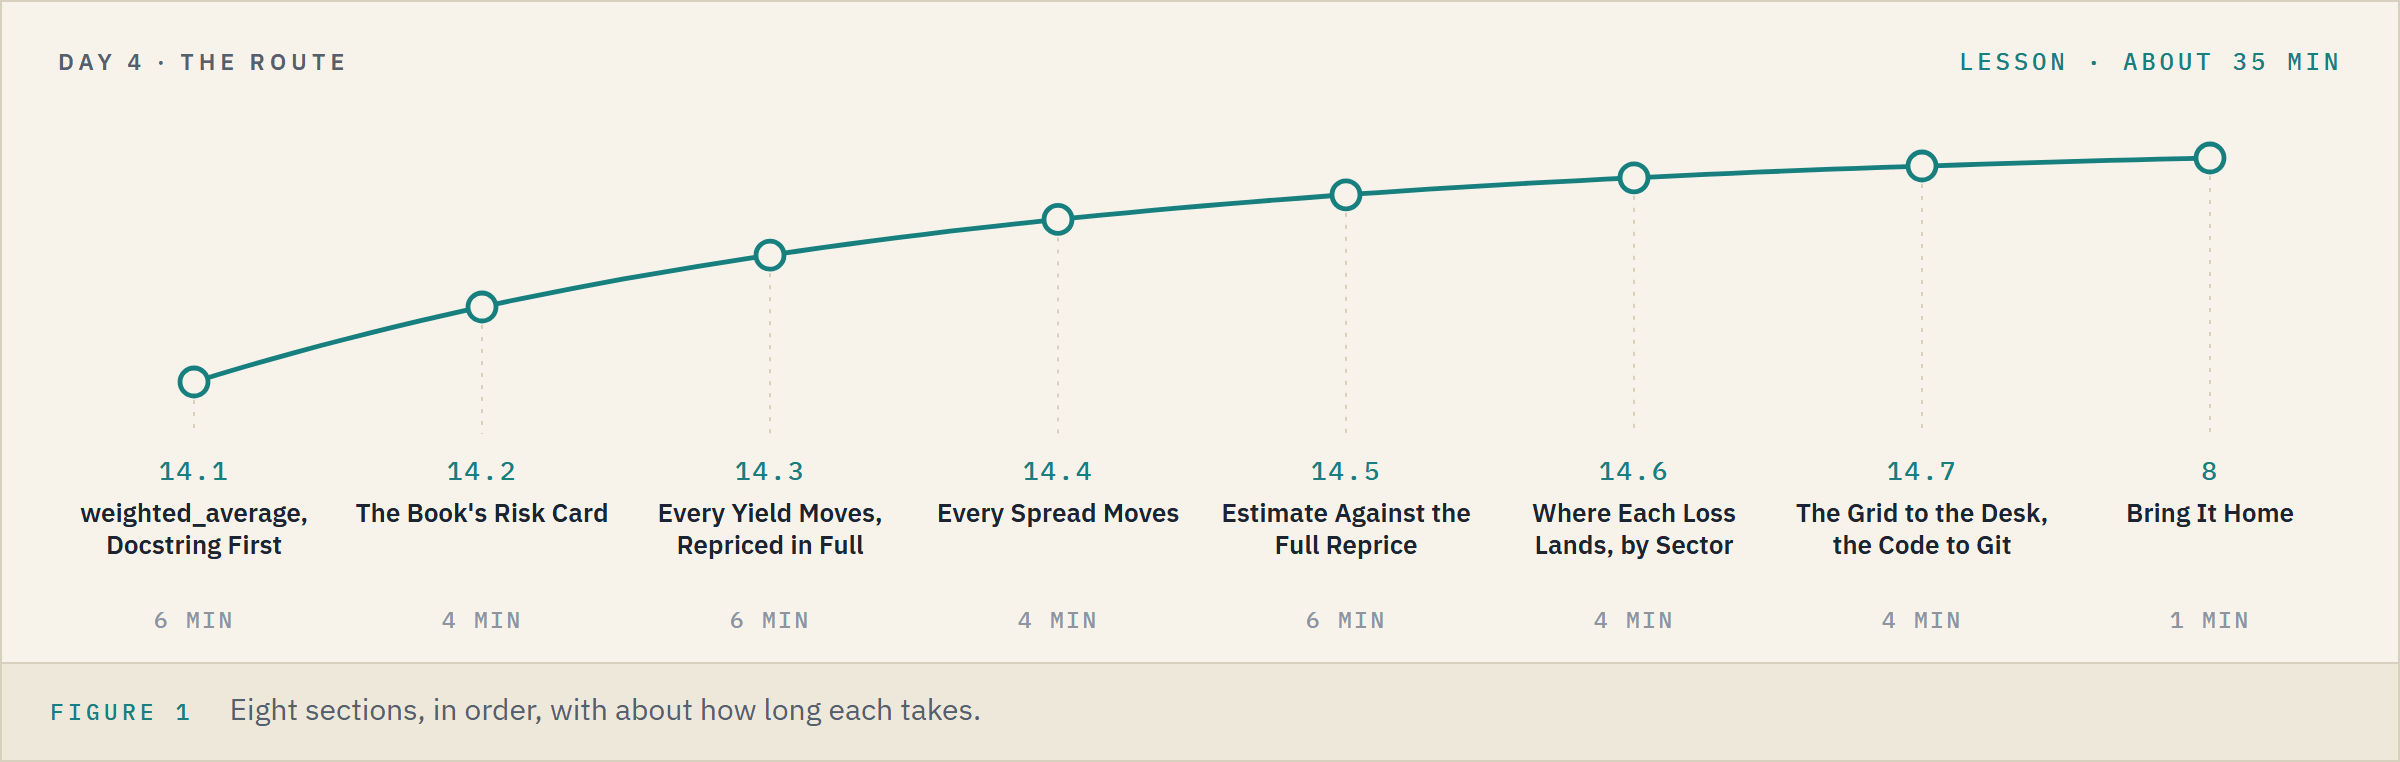

**Time.** About 35 minutes for the lesson, then about 15 for the five exercises.

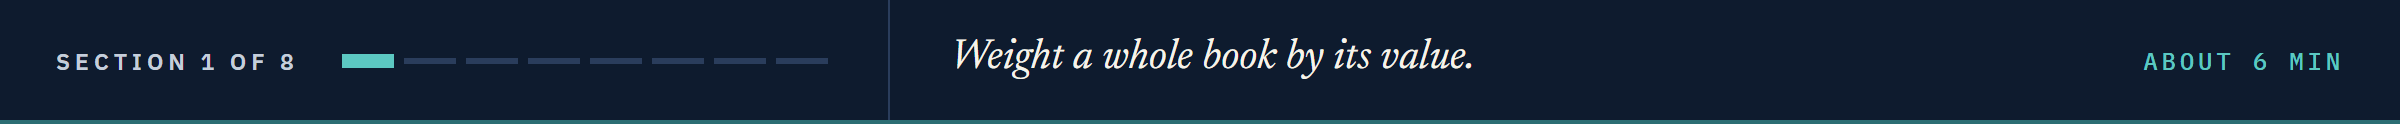

## 14.1 `weighted_average`, Docstring First

### Make Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 13 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(14)

Work folder pfi_course2_14_k4w7q2xr: 5 data files, the module as notebook 13 left it, 13 commits, tagged week1 and week2


### The Tests Pass Before We Start

The module holds 23 functions and 37 tests; today adds two functions and three tests.

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.....................................                                    [100%]
37 passed in 0.50s



### Import the Module and the Libraries

In [3]:
import importlib

import bondmath
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### Read the Book

In [4]:
holdings = pd.read_csv('holdings.csv')
# bondmath takes datetime.date values, as in notebook 06
holdings['as_of_date'] = pd.to_datetime(holdings['as_of_date']).dt.date
holdings['maturity'] = pd.to_datetime(holdings['maturity']).dt.date
total_value = holdings['market_value'].sum()
print(f'{len(holdings)} positions, {total_value:,.2f} dollars')
holdings[['cusip', 'issuer', 'sector', 'price', 'accrued', 'yield_pct', 'oas', 'par_held',
          'market_value']].head()

200 positions, 490,819,215.00 dollars


,cusip,issuer,sector,price,accrued,yield_pct,oas,par_held,market_value
0,99080CAE8,Bezane Finance,Financials,106.727,1.983,5.606,147,5000000,5435500.0
1,99049XAE2,Bezamyth Machinery,Industrials,97.556,3.679,9.220,535,250000,253087.5
2,99039NAC0,Bezoquil Freight,Transportation,98.730,1.666,5.509,153,1500000,1505940.0
3,99039NAG1,Bezoquil Freight,Transportation,92.261,2.909,6.756,218,500000,475850.0
4,99034IAD4,Bezorin Finance,Financials,92.883,2.248,5.600,127,2500000,2378275.0


`market_value` is par x (price + accrued) / 100, the dirty price; notebook 10 tied all 200 to the cent.
A book's duration weights each bond's by its market value, as the Course 1 project did: sum of value x weight, over the sum of the weights.
Course 1's Combining and Loading, Part 2, drew why the divide is by what the weights add to.

### Append It

Q. Add `weighted_average` to the module. Read the docstring first.

In [5]:
%%writefile -a bondmath.py


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight

Appending to bondmath.py


`zip` walks the two lists in step, as in Course 1.
The module takes plain lists, not pandas, so `list(...)` turns a column into one.

### The Book's Duration, Against Excel

In [6]:
importlib.reload(bondmath)
book_duration_file = bondmath.weighted_average(list(holdings['duration']),
                                               list(holdings['market_value']))
# Excel's =SUMPRODUCT(N2:N201,S2:S201)/SUM(S2:S201), from the course's Excel run
excel_duration = 6.254777411342787
print(f'weighted_average {book_duration_file:.15f}, Excel {excel_duration:.15f}')
print(f"plain average    {holdings['duration'].mean():.6f} years")

weighted_average 6.254777411342787, Excel 6.254777411342787
plain average    6.470405 years


The plain average counts every position once, whatever its size.
The larger positions here are shorter, so the weighted number is lower.

**Excel side by side.** `holdings.csv` opened in Excel: I `price`, K `accrued`, N `duration`, R `par_held`, S `market_value`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Bezane's market value (row 2)</td><td align="left"><code>par_held * (price + accrued) / 100</code></td><td align="left"><code>=R2*(I2+K2)/100</code></td><td align="left">5,435,500.00</td></tr>
<tr><td align="left">Book value</td><td align="left"><code>holdings['market_value'].sum()</code></td><td align="left"><code>=SUMPRODUCT(R2:R201,I2:I201+K2:K201)/100</code></td><td align="left">490,819,215.00</td></tr>
<tr><td align="left">Book duration</td><td align="left"><code>bondmath.weighted_average(...)</code></td><td align="left"><code>=SUMPRODUCT(N2:N201,S2:S201)/SUM(S2:S201)</code></td><td align="left">6.254777411342787</td></tr>
<tr><td align="left">Plain average</td><td align="left"><code>holdings['duration'].mean()</code></td><td align="left"><code>=AVERAGE(N2:N201)</code></td><td align="left">6.470405</td></tr>
</table>
<br clear="left">

### An Empty Group

In [7]:
try:
    bondmath.weighted_average([4.0, 6.0], [0, 0])
except ValueError as error:
    print(f'ValueError: {error}')

ValueError: the weights sum to zero


A group with no value in it has no average; the function says so instead of dividing by zero.

### Two Tests

In [8]:
%%writefile -a test_bondmath.py


def test_weighted_average_known_case():
    # (4 x 1 + 6 x 1 + 10 x 2) / (1 + 1 + 2) = 30 / 4
    assert bondmath.weighted_average([4.0, 6.0, 10.0], [1, 1, 2]) == pytest.approx(7.5, abs=1e-12)


def test_weighted_average_raises_on_zero_weights():
    with pytest.raises(ValueError):
        bondmath.weighted_average([4.0, 6.0], [0, 0])

Appending to test_bondmath.py


In [9]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................................                                  [100%]
39 passed in 0.50s



**`weighted_average` returns Excel's SUMPRODUCT over SUM to the last digit: the book's duration is 6.254777 years.**

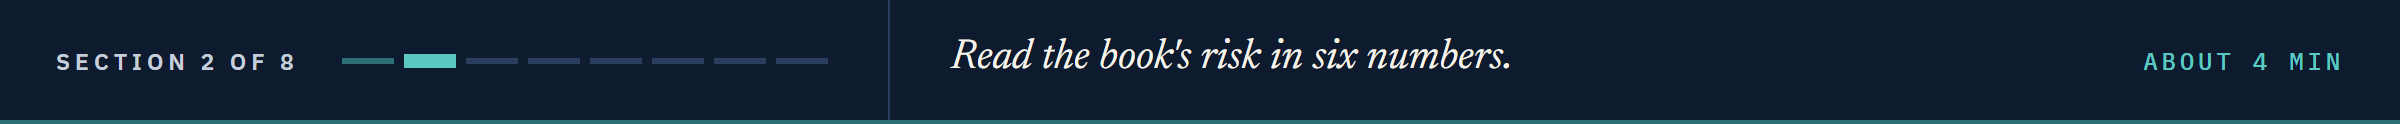

## 14.2 The Book's Risk Card

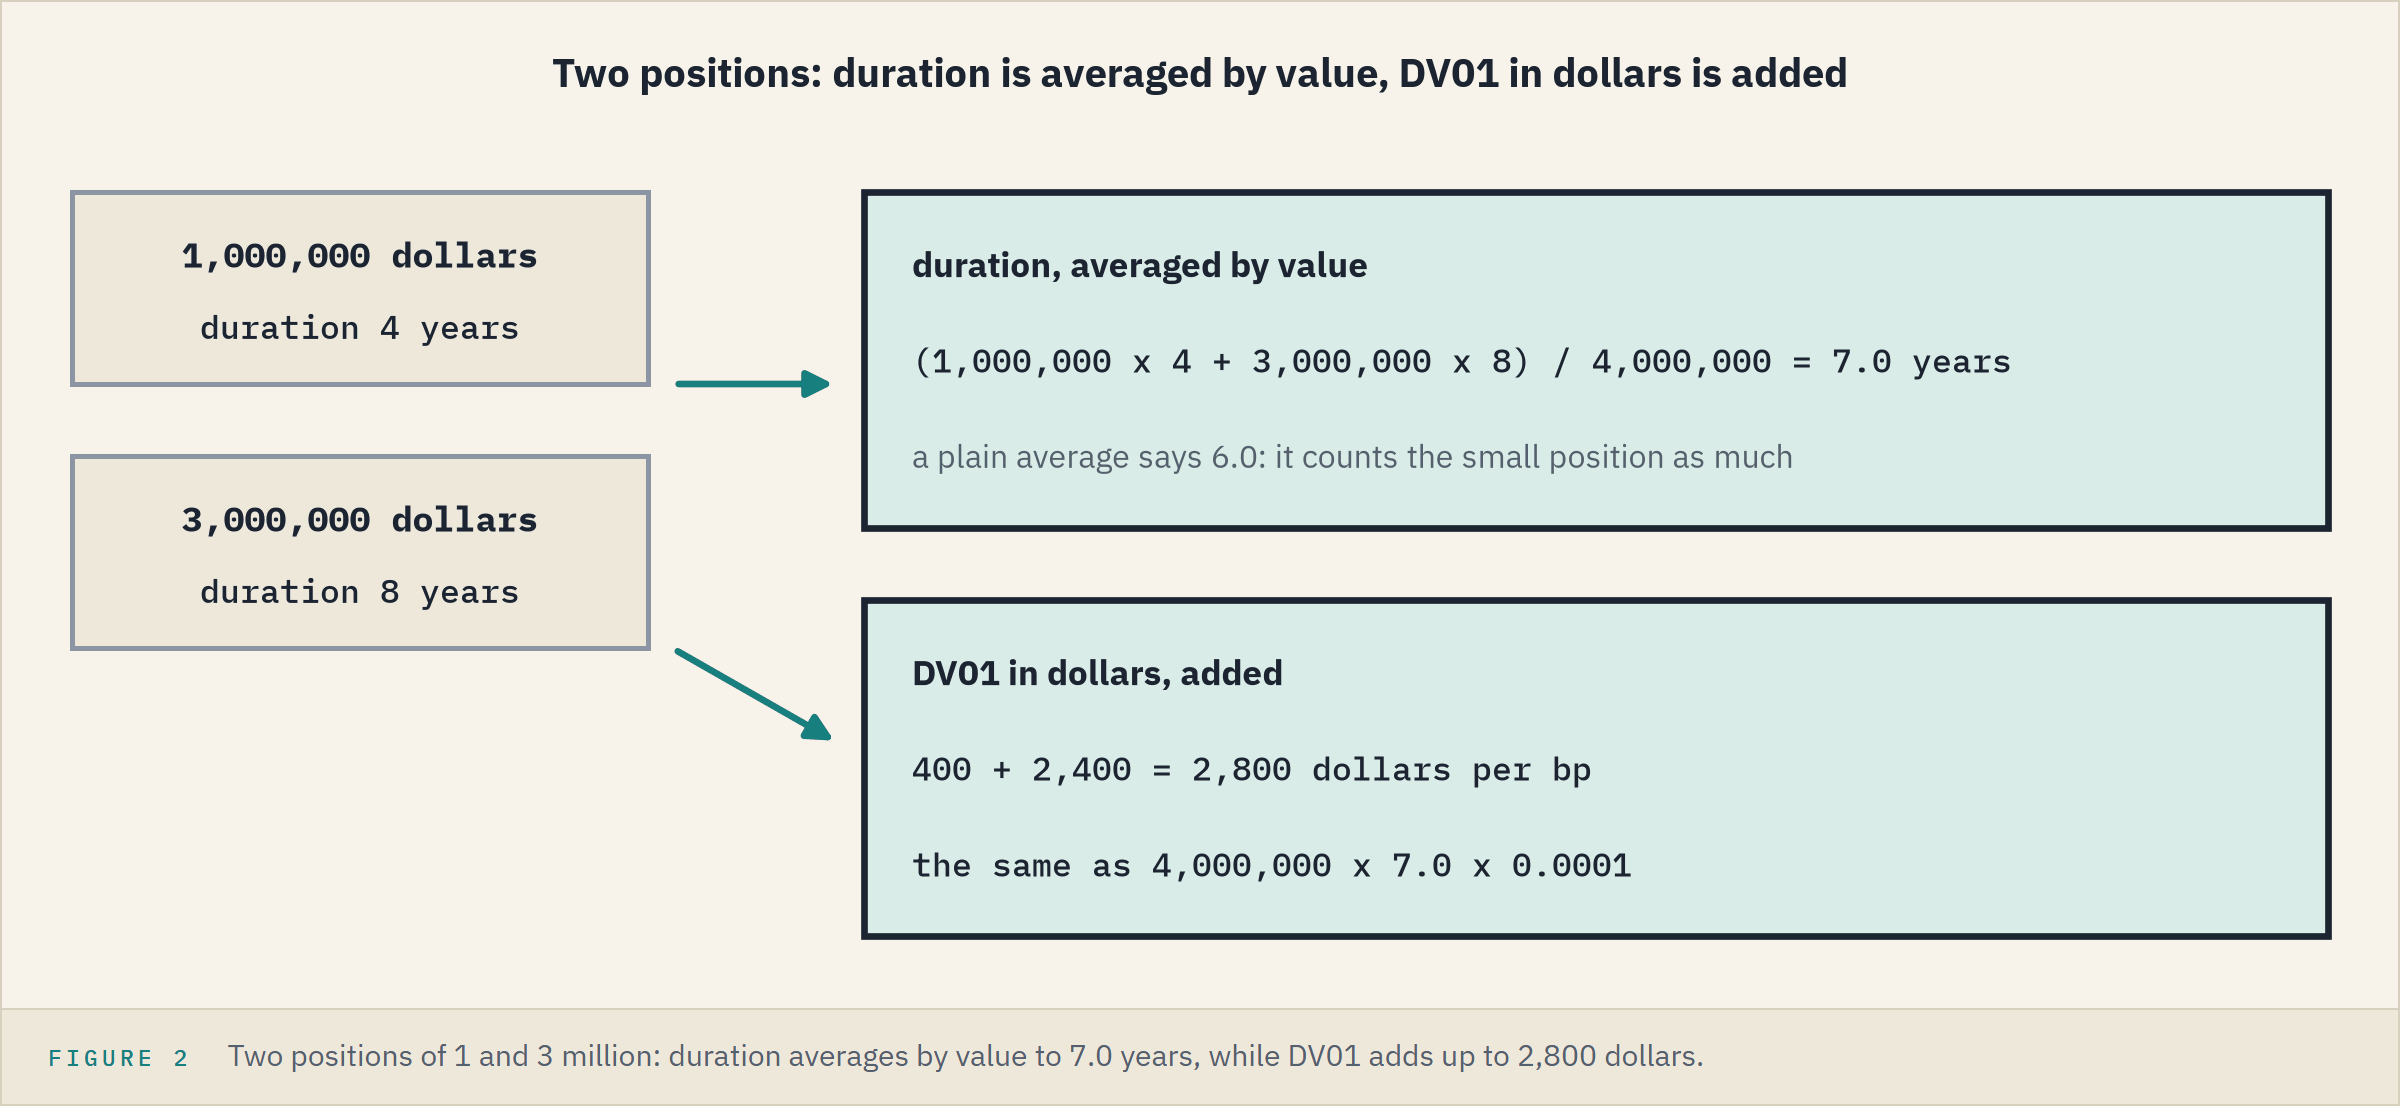

Some of a book's numbers are averages weighted by value; DV01 in dollars is a sum.
Both come from the same bonds, so they agree.

### Every Bond's Measures, From Its Yield

Q. Rebuild every bond's measures with your own functions.

In [10]:
# each bond's four inputs in one tuple; * hands them over, as in notebook 08
bonds = list(zip(holdings['as_of_date'], holdings['maturity'], holdings['coupon'],
                 holdings['yield_pct']))
holdings['dirty_bm'] = [bondmath.dirty_price(*bond) for bond in bonds]
holdings['modified_bm'] = [bondmath.modified_duration(*bond) for bond in bonds]
holdings['convexity_bm'] = [bondmath.convexity(*bond) for bond in bonds]
holdings['dts_bm'] = [bondmath.dts(bondmath.spread_duration(*bond), oas)
                      for bond, oas in zip(bonds, holdings['oas'])]

### DV01 in Dollars

In [11]:
holdings['dv01_bm'] = [bondmath.dv01(*bond) for bond in bonds]
# notebook 09's dv01 is per 100 of face: times the face held, over 100, for dollars
holdings['dv01_dollars'] = holdings['dv01_bm'] * holdings['par_held'] / 100
holdings[['cusip', 'dirty_bm', 'modified_bm', 'convexity_bm', 'dts_bm', 'dv01_dollars']].head()

,cusip,dirty_bm,modified_bm,convexity_bm,dts_bm,dv01_dollars
0,99080CAE8,108.709928,4.626971,26.358006,680.164707,2514.988172
1,99049XAE2,101.234513,2.164770,6.130346,1158.152110,54.787366
2,99039NAC0,100.395785,3.249883,12.843846,497.232069,489.411787
3,99039NAG1,95.170079,12.112785,232.886073,2640.589069,576.387357
4,99034IAD4,95.131397,7.337905,66.380211,931.914086,1745.162911


### The Book in Six Numbers

In [12]:
weights = list(holdings['market_value'])
book_duration = bondmath.weighted_average(list(holdings['modified_bm']), weights)
book_spread = bondmath.weighted_average(list(holdings['oas']), weights)
book_dts = bondmath.weighted_average(list(holdings['dts_bm']), weights)
book_convexity = bondmath.weighted_average(list(holdings['convexity_bm']), weights)
book_dv01 = holdings['dv01_dollars'].sum()

In [13]:
print(f'market value  {total_value:,.2f} dollars')
print(f'duration      {book_duration:.4f} years')
print(f'spread        {book_spread:.2f} bp')
print(f'DTS           {book_dts:.2f} years x bp')
print(f'convexity     {book_convexity:.4f} years squared')
print(f'DV01          {book_dv01:,.2f} dollars per bp')

market value  490,819,215.00 dollars
duration      6.2548 years
spread        180.46 bp
DTS           1064.11 years x bp
convexity     66.9912 years squared
DV01          306,996.11 dollars per bp


DV01 is notebook 10's number; value x duration x 0.0001 gives it to within 0.10 dollars, as that notebook's Predict found.

**Excel side by side.** Columns as in 14.1, with M `oas` and P `dts`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Book spread</td><td align="left"><code>bondmath.weighted_average(list(holdings['oas']), weights)</code></td><td align="left"><code>=SUMPRODUCT(M2:M201,S2:S201)/SUM(S2:S201)</code></td><td align="left">180.4609519769922</td></tr>
<tr><td align="left">Book DTS, the file's column</td><td align="left"><code>bondmath.weighted_average(list(holdings['dts']), weights)</code></td><td align="left"><code>=SUMPRODUCT(P2:P201,S2:S201)/SUM(S2:S201)</code></td><td align="left">1064.113487036668</td></tr>
<tr><td align="left">Book DV01, the file's durations</td><td align="left"><code>total_value * book_duration_file / 10000</code></td><td align="left"><code>=SUMPRODUCT(N2:N201,S2:S201)/10000</code></td><td align="left">306,996.49</td></tr>
</table>
<br clear="left">

Your own DTS, 1064.11, differs from the file column's by its rounding (notebook 13).
Excel's DV01 reads the file's durations, rounded to 3 decimals: 0.38 dollars above your own.

**Four of the six are averages weighted by value and DV01 is a sum: this card is the base every what-if moves from.**

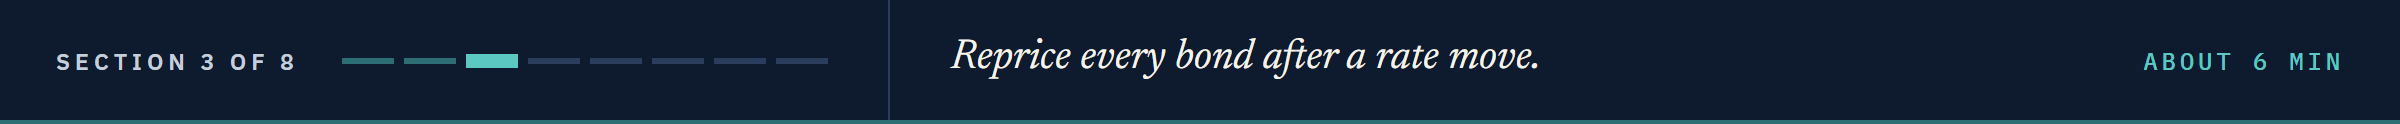

## 14.3 Every Yield Moves, Repriced in Full

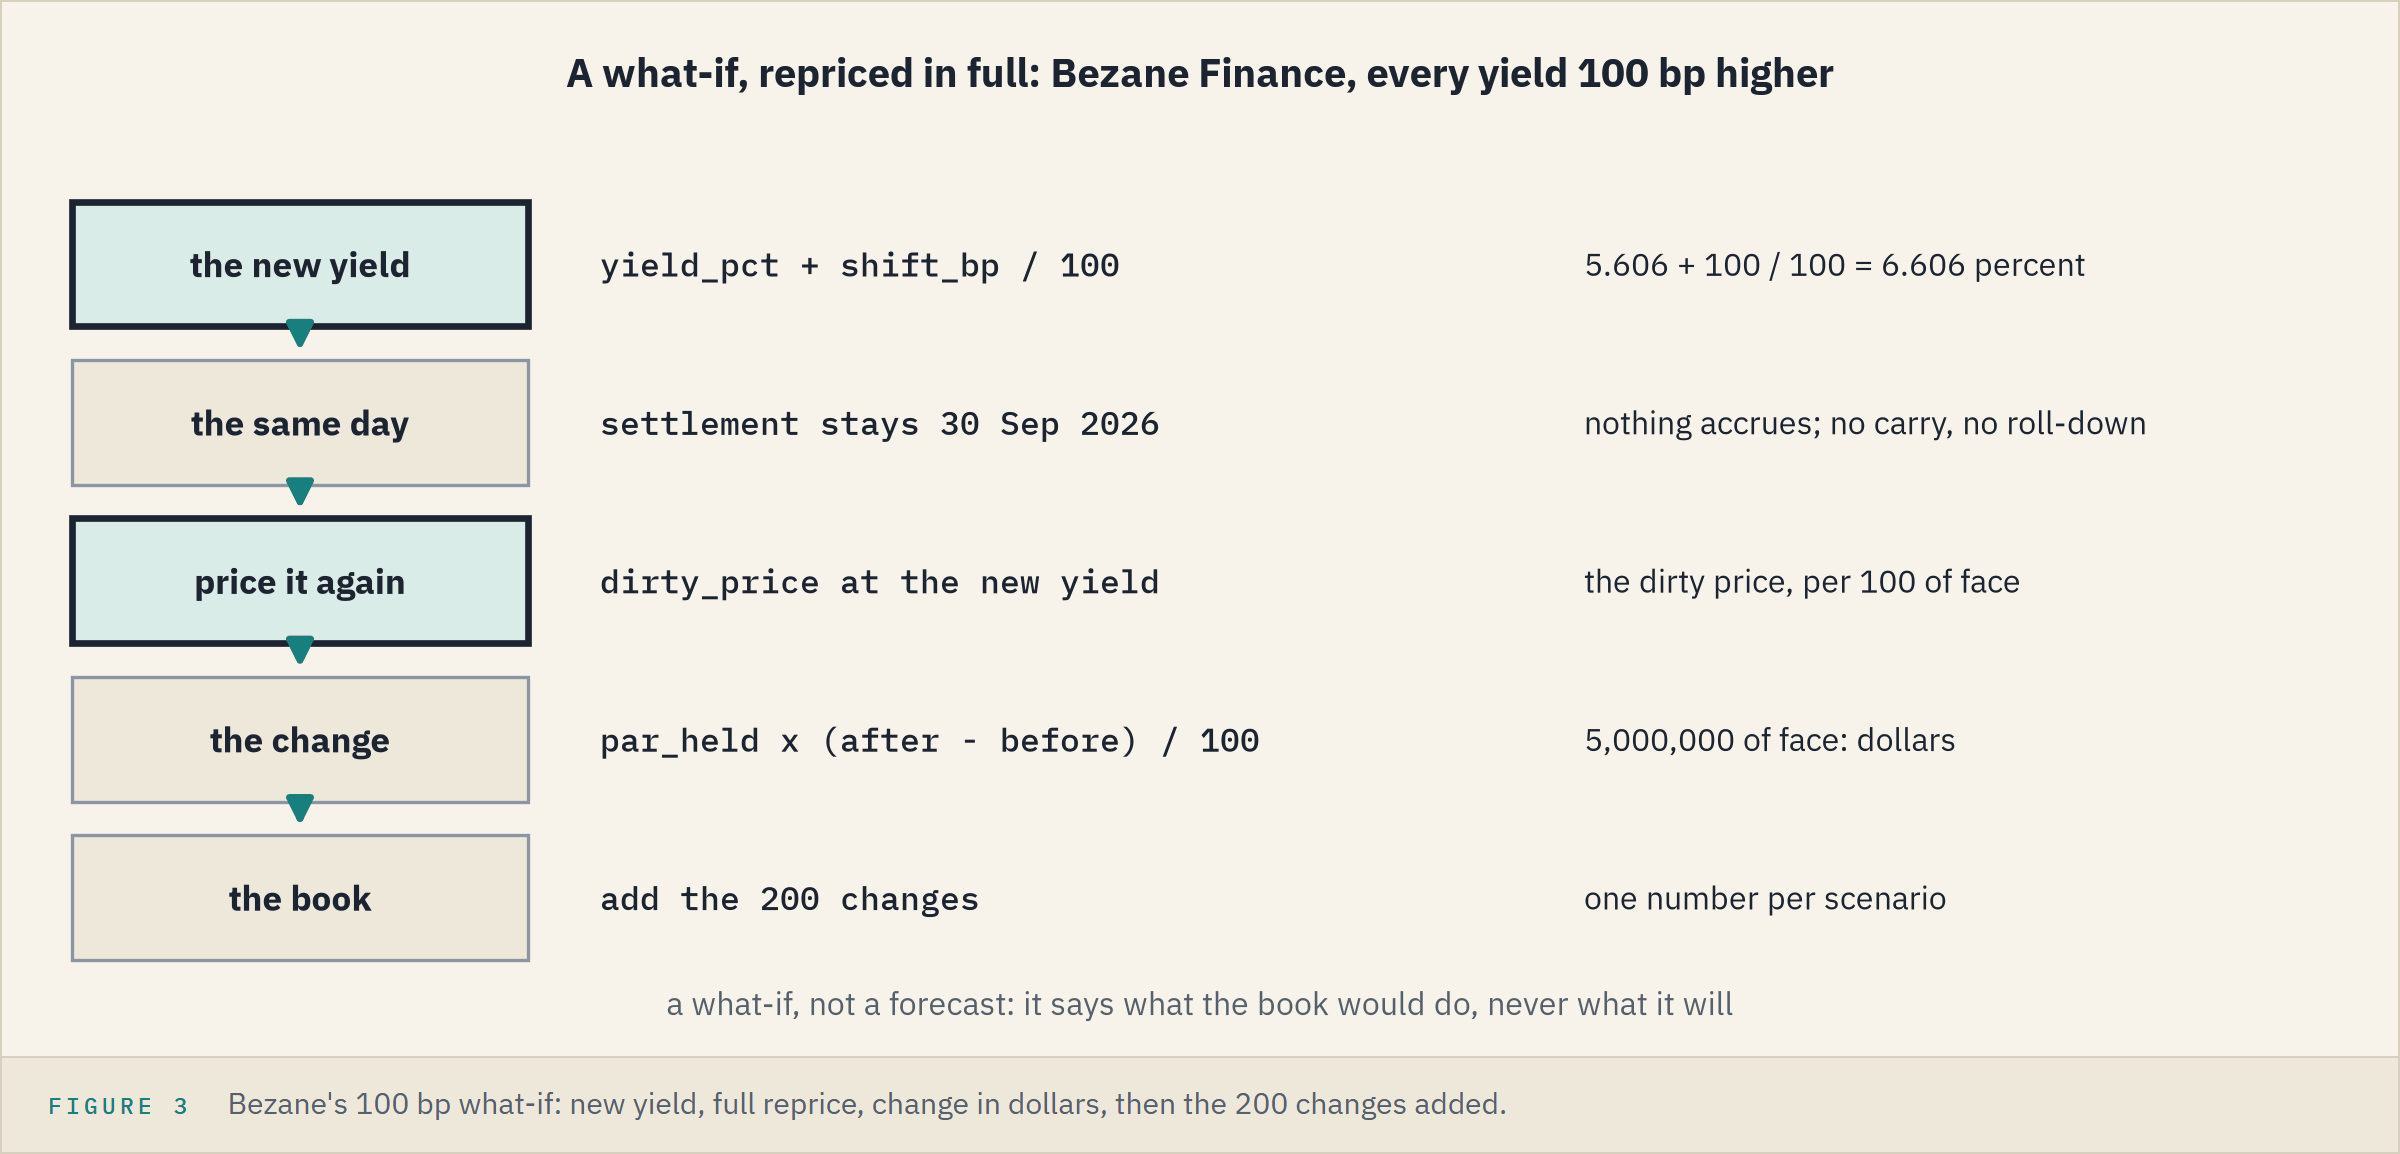

A **scenario** is a mechanical what-if, not a forecast: every yield moved at once, today, and every bond priced again.
A **parallel shift** moves every yield by the same bp.
A **full reprice** runs `dirty_price` at each new yield; no estimate stands in for it.

### The Base

In [14]:
base_value = (holdings['par_held'] * holdings['dirty_bm'] / 100).sum()
print(f'book from the yields  {base_value:,.2f} dollars')
print(f"book from the file    {total_value:,.2f} dollars, {total_value - base_value:,.2f} more")

book from the yields  490,819,038.14 dollars
book from the file    490,819,215.00 dollars, 176.86 more


The file's price and accrued are rounded to 3 decimals; every change below is measured from `base_value`, so the rounding never enters one.

### Bezane, 100 bp Higher

In [15]:
settlement, maturity, coupon_pct, yield_pct = bonds[0]
before = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct)
# 100 bp is 1 in yield_pct, which is in percent
after = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct + 100 / 100)
change_dollars = holdings.loc[0, 'par_held'] * (after - before) / 100
print(f'dirty {before:.4f} at {yield_pct} percent, {after:.4f} at {yield_pct + 1:.3f}')
print(f'the position changes by {change_dollars:,.2f} dollars')

dirty 108.7099 at 5.606 percent, 103.8202 at 6.606
the position changes by -244,484.16 dollars


**Predict 1**

Q. The book's DV01 is 306,996.11 dollars per bp. Every yield rises 100 bp at once. What does the full reprice take off the book, in millions of dollars? Write down a number.

### Four Shifts, 200 Bonds

`reprice` does Bezane's two lines for every bond, at any list of new yields.

In [16]:
def reprice(new_yields_pct):
    """Each position's change in dollars when every bond moves to its new yield."""
    after = [bondmath.dirty_price(s, m, c, y) for s, m, c, y in
             zip(holdings['as_of_date'], holdings['maturity'], holdings['coupon'], new_yields_pct)]
    return holdings['par_held'] * (pd.Series(after) - holdings['dirty_bm']) / 100

In [17]:
# an empty table: each pass of the loop adds a column
pnl = pd.DataFrame()
for shift_bp in [-100, -25, 25, 100]:
    # :+d writes the sign, as notebook 03's :+.4f
    pnl[f'rates {shift_bp:+d} bp'] = reprice(holdings['yield_pct'] + shift_bp / 100)
totals = pnl.sum()
print(f"a 100 bp fall gains {totals.iloc[0] + totals.iloc[3]:,.2f} dollars more than a rise loses")
totals.round(2)

a 100 bp fall gains 3,296,147.87 dollars more than a rise loses


rates -100 bp    32430983.84
rates -25 bp      7778969.05
rates +25 bp     -7573434.14
rates +100 bp   -29134835.97
dtype: float64

29.13 million: 1.56 million less than DV01 x 100 says.
The fall gains more than the rise loses: convexity, the bend notebook 10 measured.

### Draw It

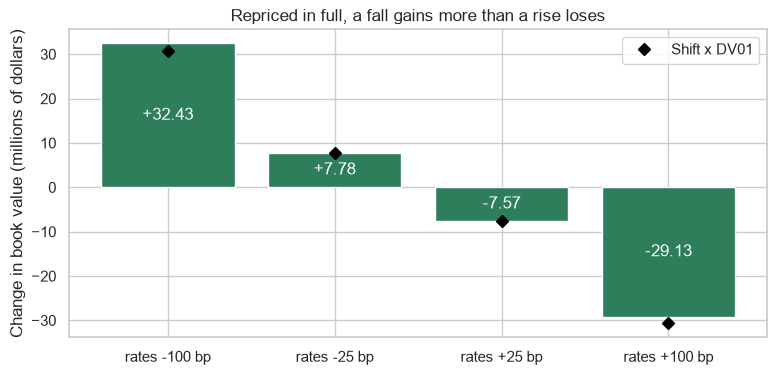

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(totals.index, totals / 1e6)
# fmt with {} formats as an f-string does: the sign and two decimals
# label_type='center' writes each number inside its bar, as in Course 1's Analyzing Text
ax.bar_label(bars, fmt='{:+.2f}', label_type='center', color='white')
# DV01's straight line: minus the shift times the book's DV01
straight = [-shift_bp * book_dv01 / 1e6 for shift_bp in [-100, -25, 25, 100]]
ax.plot(totals.index, straight, marker='D', linestyle='none', color='black', label='Shift x DV01')
ax.set_title('Repriced in full, a fall gains more than a rise loses')
ax.set_ylabel('Change in book value (millions of dollars)')
ax.legend()
plt.show()

### DV01 for 25 bp

In [19]:
by_dv01 = 25 * book_dv01
# the two 25 bp reprices averaged: their bends cancel, almost
average_25 = (totals['rates -25 bp'] - totals['rates +25 bp']) / 2
print(f'25 x book DV01            {by_dv01:,.2f} dollars')
print(f'the two reprices averaged {average_25:,.2f} dollars')

25 x book DV01            7,674,902.76 dollars
the two reprices averaged 7,676,201.59 dollars


DV01 is the slope at today's yields; for 25 bp it is within 1,300 dollars of the reprice.

**Excel side by side.** One column reprices the book at the shift in Y1, and a Data Table runs it for every shift.

A `holdings.csv` sheet as in 14.1, with A `as_of_date`, G `coupon`, H `maturity`, L `yield_pct`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">A bond at the shifted yield (V2)</td><td align="left"><code>bondmath.dirty_price(..., yield_pct + shift_bp / 100)</code></td><td align="left"><code>=PRICE(A2,H2,G2/100,(L2+$Y$1/100)/100,100,2,0)</code></td><td align="left">filled down</td></tr>
<tr><td align="left">Its value (W2)</td><td align="left"><code>par_held * dirty / 100</code></td><td align="left"><code>=R2*(V2+K2)/100</code></td><td align="left">filled down</td></tr>
<tr><td align="left">The book (AA2)</td><td align="left"><code>.sum()</code></td><td align="left"><code>=SUM(W2:W201)</code></td><td align="left">490,818,946.75 at 0</td></tr>
<tr><td align="left">Every shift at once</td><td align="left">the loop over <code>reprice</code></td><td align="left">shifts in Z3:Z7; Data, What-If Analysis, Data Table, column input Y1: <code>=TABLE(,Y1)</code></td><td align="left">461,684,110.78 at +100</td></tr>
</table>
<br clear="left">

The +100 row less the 0 row is -29,134,835.97, equal to Python's within 3e-07 dollars on all four shifts.
The 0 row sits 91.39 under `base_value`: the file's rounded `accrued`, which cancels in every change.

**A 100 bp rise takes 29.13 million dollars off the book, 1.56 million less than DV01's straight line, and Excel's Data Table agrees to the cent.**

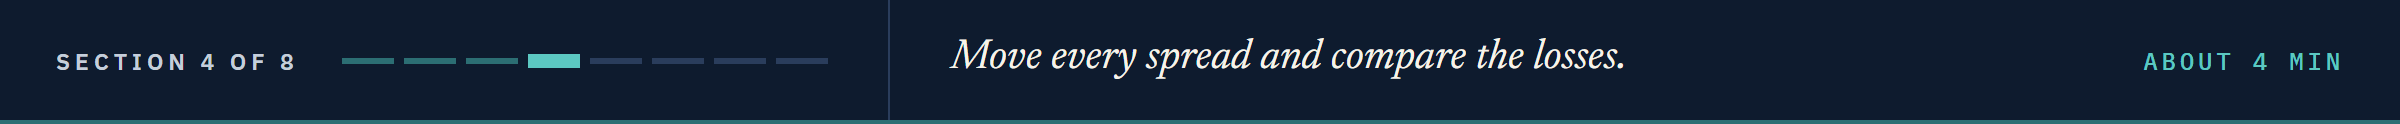

## 14.4 Every Spread Moves

Notebook 12 found the file's rule: each yield is the curve at its maturity plus its spread.
Now the curve stays where it is and the spreads move.

**Predict 2**

Q. Every spread up 25 bp, against 14.3's every yield up 25 bp, bond by bond:

A) the same to the cent: both move every yield 25 bp

B) a few dollars apart: the curve stays put

C) thousands apart: spread duration is not duration

### Every Spread Up 25 bp

In [20]:
pnl['spreads +25 bp'] = reprice(holdings['yield_pct'] + 25 / 100)
gap = (pnl['spreads +25 bp'] - pnl['rates +25 bp']).abs().max()
print(f"spreads +25 bp: {pnl['spreads +25 bp'].sum():,.2f} dollars")
print(f'largest difference from rates +25 bp, over 200 bonds: {gap:.2f} dollars')

spreads +25 bp: -7,573,434.14 dollars
largest difference from rates +25 bp, over 200 bonds: 0.00 dollars


A: the same to the cent.
With the curve held, 25 bp of spread is 25 bp of yield, as notebook 13 found.

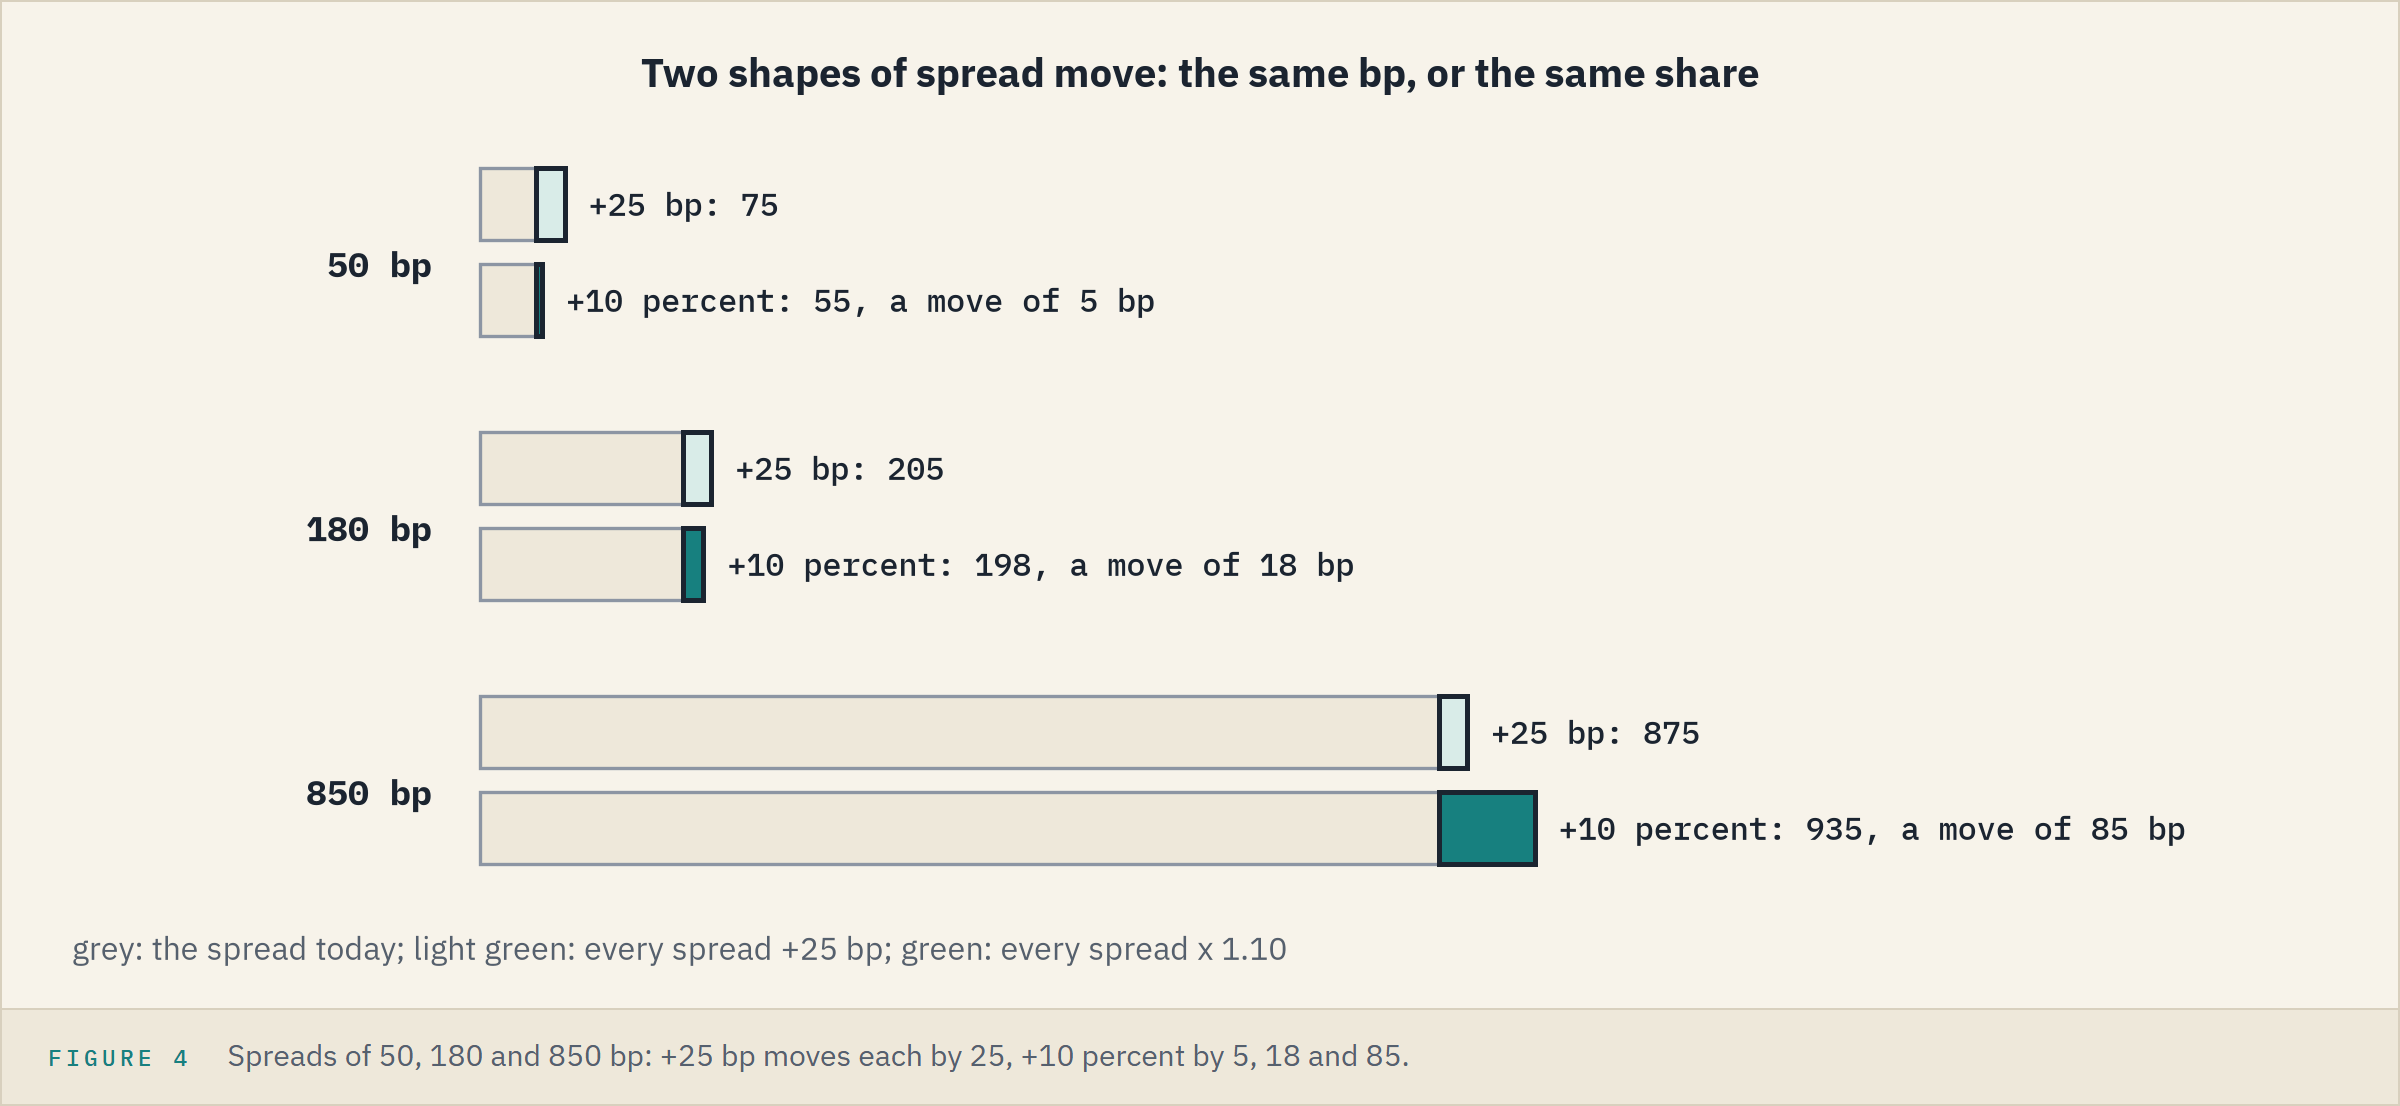

Notebook 13's DTS source found that wider spreads move more, so a desk runs a second shape.
A **proportional spread move** takes each spread times 1.10: the wide bonds move most.
Both shapes are mechanical what-ifs, not forecasts.

### Every Spread Up 10 Percent

In [21]:
# a tenth of each spread; oas is in bp, so / 100 for yield_pct
pnl['spreads +10 percent'] = reprice(holdings['yield_pct'] + 0.10 * holdings['oas'] / 100)
spread_10 = pnl['spreads +10 percent'].sum()
print(f'spreads +10 percent: {spread_10:,.2f} dollars, {spread_10 / base_value * 100:.4f} percent')

spreads +10 percent: -5,150,093.57 dollars, -1.0493 percent


The book's spread is 180.46 bp, so its average move is about 18 bp: less than 25, and so a smaller loss.

### Book DTS Gives It

Notebook 13's rule: a spread 10 percent wider moves the price about -DTS x 0.10 / 100 percent.

In [22]:
from_dts = -book_dts * 0.10 / 100
print(f'from book DTS  {from_dts:.4f} percent')
print(f'full reprice   {spread_10 / base_value * 100:.4f} percent')

from book DTS  -1.0641 percent
full reprice   -1.0493 percent


**25 bp on every spread costs 7.57 million, 10 percent of every spread 5.15 million, and book DTS gives the second within 0.015 percent of value.**

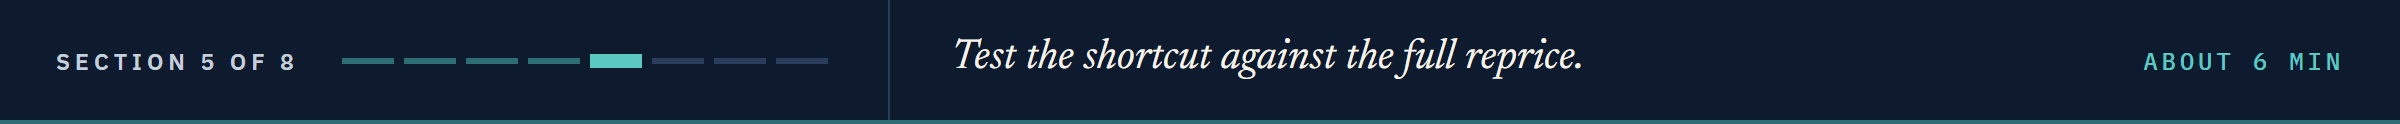

## 14.5 `price_change_estimate`, Against the Full Reprice

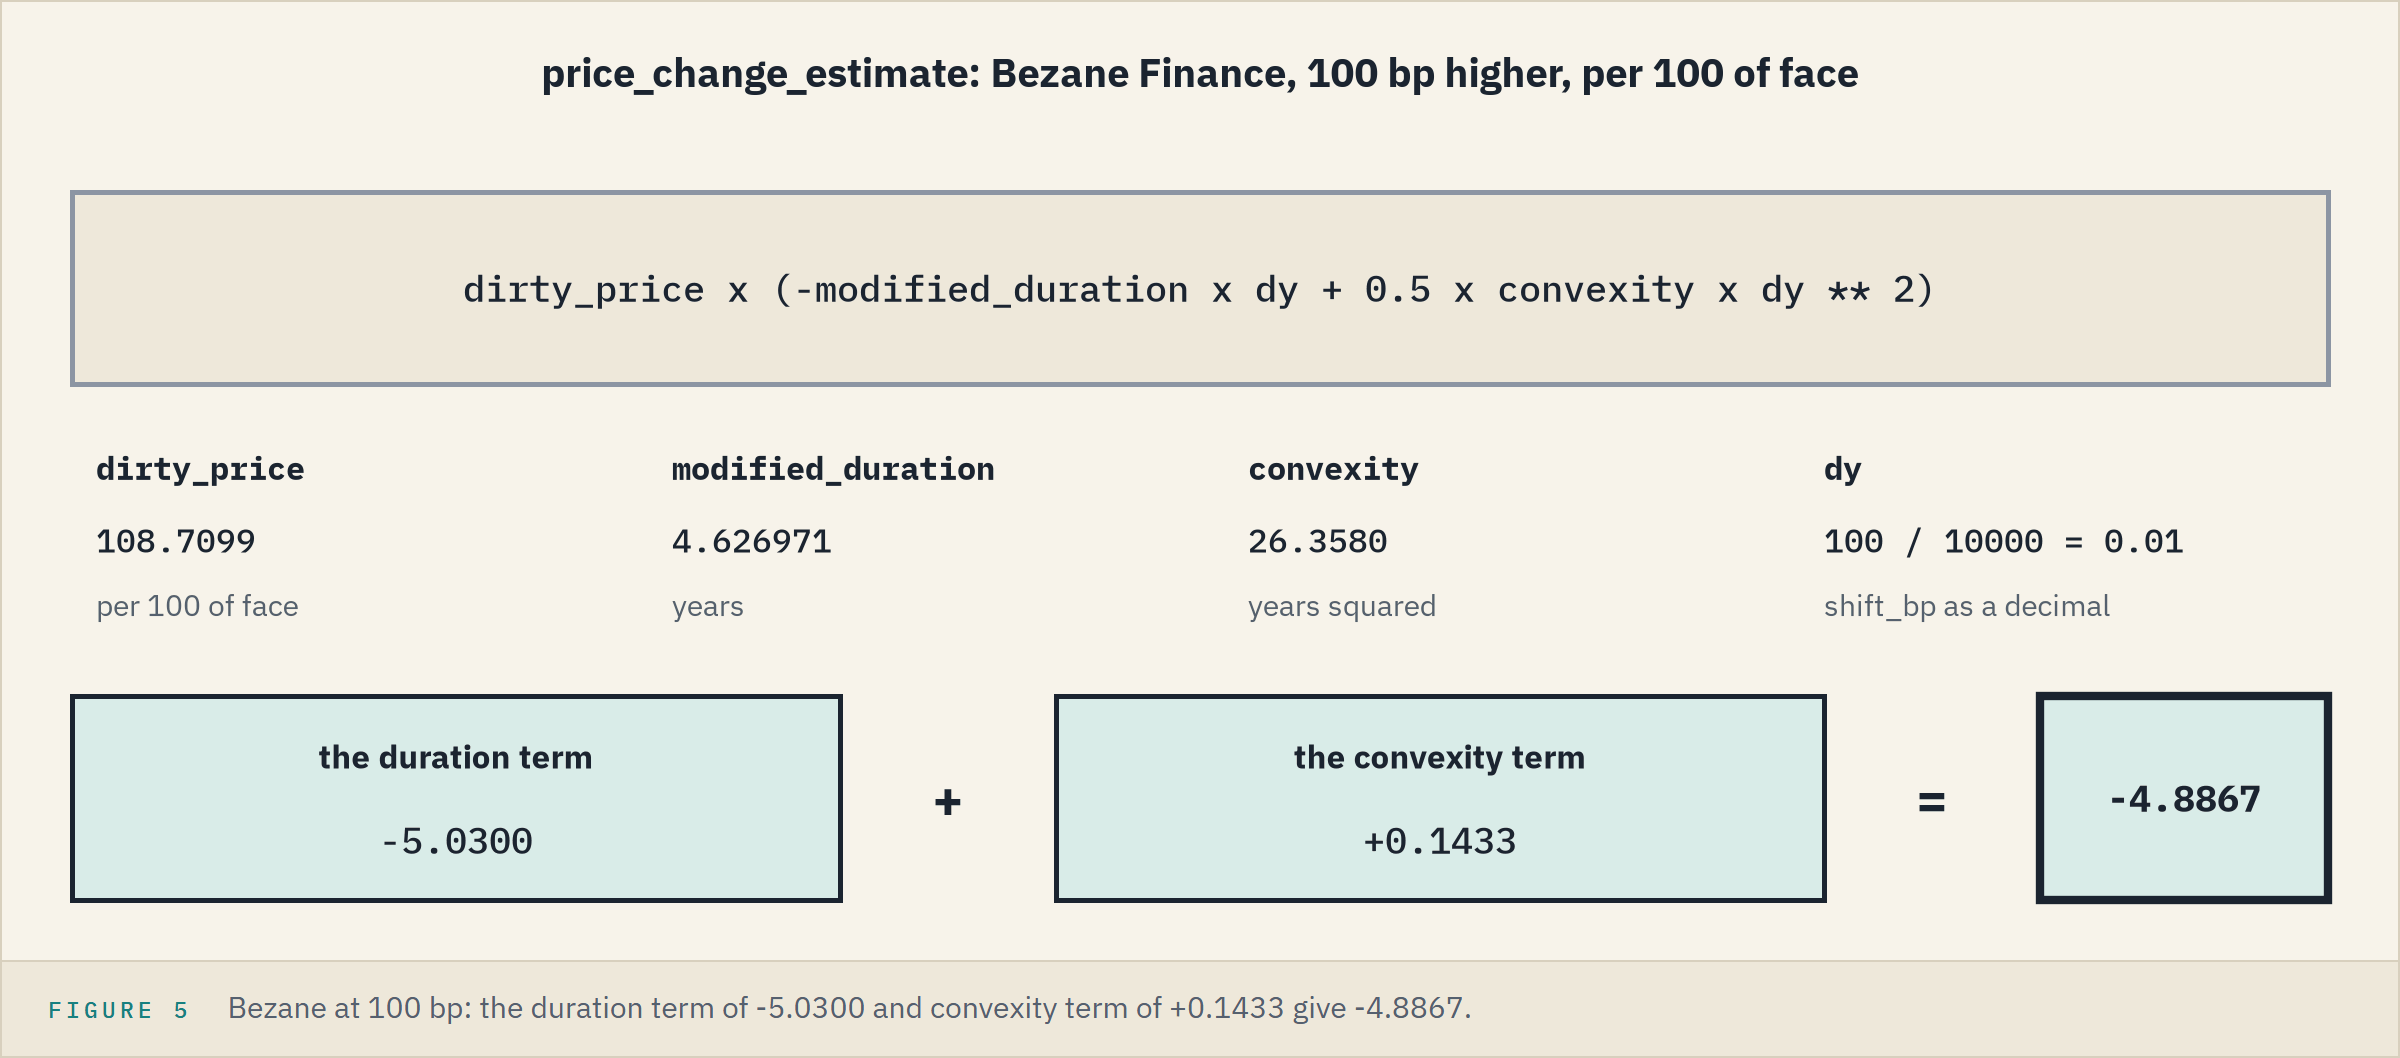

Notebook 10 built this estimate from two terms; now it goes in the module.
The pieces: the dirty price per 100, modified duration in years, convexity in years squared, and dy = shift_bp / 10000.

### Append It

In [23]:
%%writefile -a bondmath.py


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Appending to bondmath.py


### Bezane, 100 bp

In [24]:
importlib.reload(bondmath)
bezane = holdings.iloc[0]
modified, convexity = bezane['modified_bm'], bezane['convexity_bm']
with_convexity = bondmath.price_change_estimate(before, modified, convexity, 100)
duration_only = bondmath.price_change_estimate(before, modified, 0.0, 100)
print(f'full reprice            {after - before:.4f} per 100')
print(f'duration and convexity  {with_convexity:.4f} per 100')
print(f'duration alone          {duration_only:.4f} per 100')

full reprice            -4.8897 per 100
duration and convexity  -4.8867 per 100
duration alone          -5.0300 per 100


Duration alone misses by 0.14 per 100; the convexity term takes the miss to 0.003.

### The Third Test

At 5 bp the estimate should match a full reprice of every holdings row of the reference file to 0.0001 per 100.
The test keeps those rows with a comprehension's `if`, as Course 1 filtered lists.

In [25]:
%%writefile -a test_bondmath.py


def test_estimate_close_to_full_reprice_for_small_shift():
    shift_bp = 5
    # the 200 holdings rows of the reference file, Excel's inputs
    rows = [row for row in REFERENCE if row["group"] == "holdings"]
    for row in rows:
        settlement, maturity, coupon_pct, yield_pct, frequency, basis = bond_inputs(row)
        # full reprice: the dirty price after the shift minus the dirty price before
        before = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
        after = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct + shift_bp / 100, frequency, basis)
        # the estimate from duration and convexity
        duration_years = bondmath.modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
        convexity_years2 = bondmath.convexity(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
        estimate = bondmath.price_change_estimate(before, duration_years, convexity_years2, shift_bp)
        assert estimate == pytest.approx(after - before, abs=1e-4), row["case_id"]

Appending to test_bondmath.py


In [26]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................................                                 [100%]
40 passed in 0.50s



### The Estimate for the Book

`estimate` is `reprice`'s twin: the shortcut for every bond, at each bond's own shift in bp.

In [27]:
def estimate(shifts_bp):
    """Each position's estimated change in dollars, from duration and convexity."""
    per_100 = [bondmath.price_change_estimate(p, d, c, s) for p, d, c, s in
               zip(holdings['dirty_bm'], holdings['modified_bm'], holdings['convexity_bm'],
                   shifts_bp)]
    return holdings['par_held'] * pd.Series(per_100) / 100

### The 25 bp Moves

In [28]:
for shift_bp in [-25, 25]:
    full = totals[f'rates {shift_bp:+d} bp']
    # a list times a number repeats it, as in Course 1: one shift for each bond
    miss = full - estimate([shift_bp] * len(holdings)).sum()
    print(f'{shift_bp:+d} bp: full {full:,.2f}, the shortcut misses by {miss:,.2f} dollars')

-25 bp: full 7,778,969.05, the shortcut misses by 1,314.62 dollars
+25 bp: full -7,573,434.14, the shortcut misses by -1,283.05 dollars


**Predict 3**

Q. At 25 bp the shortcut misses the full reprice by about 1,300 dollars. At 100 bp, four times the move, by how many dollars? Write down a number.

### All Six Scenarios

In [29]:
# each column holds every bond's shift in bp; a single number fills its column
shifts = pd.DataFrame({'rates -100 bp': -100, 'rates -25 bp': -25, 'rates +25 bp': 25,
                       'rates +100 bp': 100, 'spreads +25 bp': 25,
                       'spreads +10 percent': 0.10 * holdings['oas']})
grid = pd.DataFrame({'full_dollars': pnl.sum()})
grid['full_pct'] = grid['full_dollars'] / base_value * 100
grid['estimate_dollars'] = [estimate(shifts[name]).sum() for name in grid.index]
grid['miss_dollars'] = grid['full_dollars'] - grid['estimate_dollars']
grid.round(2)

,full_dollars,full_pct,estimate_dollars,miss_dollars
rates -100 bp,32430983.84,6.61,32343637.85,87345.99
rates -25 bp,7778969.05,1.58,7777654.44,1314.62
rates +25 bp,-7573434.14,-1.54,-7572151.08,-1283.05
rates +100 bp,-29134835.97,-5.94,-29055584.23,-79251.74
spreads +25 bp,-7573434.14,-1.54,-7572151.08,-1283.05
spreads +10 percent,-5150093.57,-1.05,-5148828.79,-1264.78


About 87,000 down and 79,000 up: 66 and 62 times the 25 bp misses, not four.
The miss grows about as the cube of the move, 4 x 4 x 4 = 64: the term the shortcut leaves out.

### Draw It

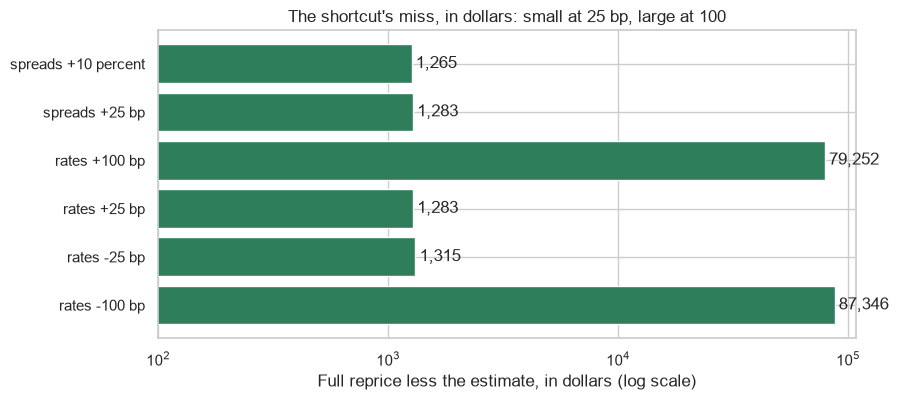

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(grid.index, grid['miss_dollars'].abs())
# the misses span three powers of ten, so the axis is logarithmic
ax.set_xscale('log')
# start the axis at 100 dollars, so the short bars keep their length
ax.set_xlim(left=100)
ax.bar_label(bars, fmt='{:,.0f}', padding=3)
ax.set_title("The shortcut's miss, in dollars: small at 25 bp, large at 100")
ax.set_xlabel('Full reprice less the estimate, in dollars (log scale)')
plt.show()

**For 25 bp the shortcut misses by about 1,300 dollars on 7.6 million; for 100 bp by 79,000 to 87,000: quote the full reprice for a large move.**

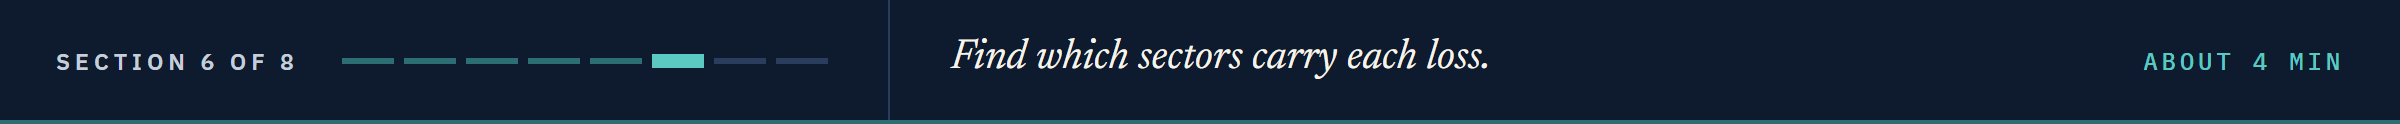

## 14.6 Where Each Loss Lands, by Sector

### Sums by Sector

A weighted average splits into sums, so `groupby` can add each piece by sector and divide after.
`duration` is the file's, as the Excel pivot reads it.

In [31]:
holdings['mv_x_duration'] = holdings['market_value'] * holdings['duration']
holdings['mv_x_dts'] = holdings['market_value'] * holdings['dts_bm']
sums = holdings.groupby('sector')[['market_value', 'mv_x_duration', 'mv_x_dts',
                                    'dv01_dollars']].sum()
# the parts must add back to the book
assert abs(sums['market_value'].sum() - total_value) < 0.005
assert abs(sums['dv01_dollars'].sum() - book_dv01) < 1e-6

### Divided Back

In [32]:
by_sector = pd.DataFrame({'weight_pct': sums['market_value'] / total_value * 100,
                          'duration': sums['mv_x_duration'] / sums['market_value'],
                          'dts': sums['mv_x_dts'] / sums['market_value'],
                          'dv01_share_pct': sums['dv01_dollars'] / book_dv01 * 100})
print(f"Transportation's duration {by_sector.loc['Transportation', 'duration']:.12f} years")
by_sector.sort_values('weight_pct', ascending=False).round(2)

Transportation's duration 8.186803162389 years


,weight_pct,duration,dts,dv01_share_pct
sector,,,,
Materials,14.61,5.26,863.68,12.29
Financials,13.90,6.22,1006.25,13.82
Consumer,11.54,6.97,1395.78,12.86
Telecom,11.38,6.16,1090.25,11.20
Industrials,10.70,6.70,1567.20,11.46
Transportation,9.95,8.19,914.17,13.02
Health Care,7.93,5.13,637.25,6.50
Energy,7.91,6.06,1025.17,7.67
Technology,6.18,5.47,869.87,5.40


**Excel side by side.** A helper column `mv_x_duration`, `=S2*N2`, filled down, then a PivotTable: `sector` in Rows, Sum of `market_value`, and a calculated field `=mv_x_duration/market_value`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Transportation's duration</td><td align="left"><code>by_sector.loc['Transportation', 'duration']</code></td><td align="left">the calculated field's cell</td><td align="left">8.186803162389122</td></tr>
<tr><td align="left">The whole book</td><td align="left"><code>bondmath.weighted_average(...)</code></td><td align="left">Grand Total</td><td align="left">6.254777411342787</td></tr>
</table>
<br clear="left">

The pivot equals `groupby` in all ten sectors, within 1e-15 years.

**Predict 4**

Q. Transportation is 9.9 percent of the value, with the longest duration, 8.19 years, and a DTS of 914 against the book's 1,064. Its share of the loss when every spread widens 10 percent is:

A) above 9.9 percent

B) about 9.9 percent

C) below 9.9 percent

### Each Scenario's Loss by Sector

In [33]:
# pnl has no sector column: group its rows by the book's, one label per row
sector_pnl = pnl.groupby(holdings['sector']).sum()
# every column adds back to the book's change
assert np.isclose(sector_pnl.sum(), pnl.sum()).all()
shares = sector_pnl / sector_pnl.sum() * 100
compare = pd.DataFrame({'value': by_sector['weight_pct'],
                        'rates +100 bp': shares['rates +100 bp'],
                        'spreads +10 percent': shares['spreads +10 percent']})
compare.loc[['Transportation', 'Consumer', 'Industrials']].round(2)

,value,rates +100 bp,spreads +10 percent
sector,,,
Transportation,9.95,12.80,8.59
Consumer,11.54,12.78,15.03
Industrials,10.70,11.43,15.75


C: 8.6 percent of the spread loss, on 9.9 percent of the value, and 12.8 percent of the +100 bp loss.

### Draw It

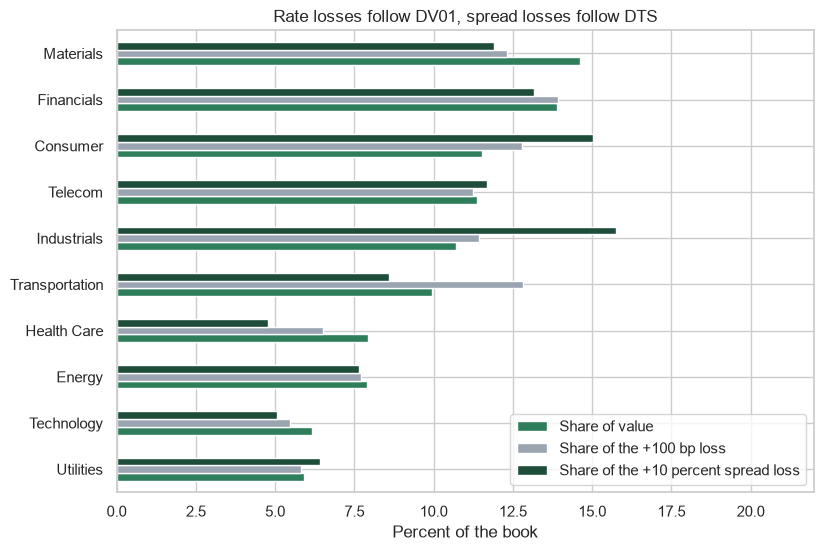

In [34]:
fig, ax = plt.subplots(figsize=(9, 6))
# ax=ax draws pandas' bars on these axes, as in notebook 13
compare.sort_values('value').plot.barh(ax=ax)
ax.set_title('Rate losses follow DV01, spread losses follow DTS')
ax.set_xlabel('Percent of the book')
ax.set_ylabel('')
# room on the right for the legend
ax.set_xlim(0, 22)
# a list of labels names the bars in the columns' order
ax.legend(['Share of value', 'Share of the +100 bp loss', 'Share of the +10 percent spread loss'],
          loc='lower right')
plt.show()

Long sectors carry more of a rate loss than their value; those with a high DTS carry more of a proportional spread loss.
This describes an invented book; it ranks nothing.

**A rate move lands where the DV01 sits and a proportional spread move where the DTS sits: Transportation is 9.9 percent of the value, 12.8 percent of the +100 bp loss, and 8.6 percent of the +10 percent spread loss.**

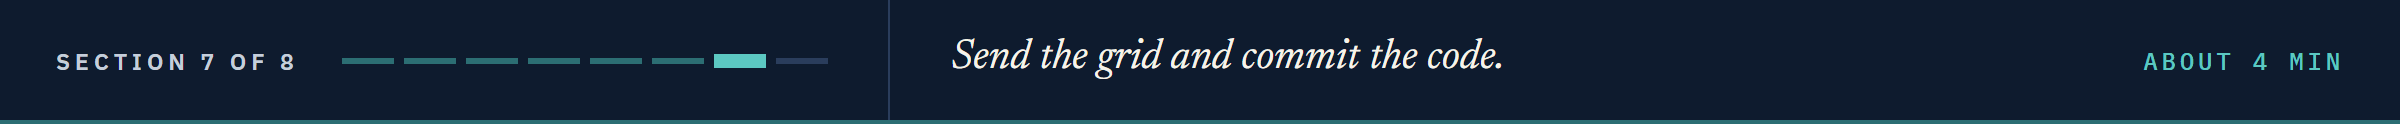

## 14.7 The Grid to the Desk, the Code to Git

### The Workbook

In [35]:
# Course 1's ExcelWriter: two sheets in one file, in the work folder
with pd.ExcelWriter('scenario_grid.xlsx') as writer:
    grid.round(2).to_excel(writer, sheet_name='scenarios')
    sector_pnl.round(2).to_excel(writer, sheet_name='by_sector')

### Read It Back

In [36]:
back = pd.read_excel('scenario_grid.xlsx', sheet_name=None, index_col=0)
assert np.isclose(back['scenarios'], grid.round(2)).all()
assert np.isclose(back['by_sector'], sector_pnl.round(2)).all()
print(list(back.keys()), 'read back, every number as written')

['scenarios', 'by_sector'] read back, every number as written


### What Git Sees

In [37]:
!git -C "{work}" status --short

 M bondmath.py
 M test_bondmath.py
?? scenario_grid.xlsx


` M` beside the two files you appended to; `??` beside the workbook, which Git has never seen.

### Staged by Habit

In [38]:
!git -C "{work}" add bondmath.py test_bondmath.py scenario_grid.xlsx
!git -C "{work}" status --short

M  bondmath.py
A  scenario_grid.xlsx
M  test_bondmath.py


`A` means staged as a new file: the workbook would go into the commit.
It is output, made again by running the notebook; the record keeps code.

### Take It Back

`git restore --staged` takes a file out of the staging area and leaves it in the folder, unlike notebook 04's `git restore`, which undoes the edit itself.

In [39]:
!git -C "{work}" restore --staged scenario_grid.xlsx
!git -C "{work}" status --short

M  bondmath.py
M  test_bondmath.py
?? scenario_grid.xlsx


### Commit the Code

In [40]:
subject = 'Notebook 14: weighted_average and price_change_estimate'
body = 'Notebook 14 rolls the bonds up into a book and reprices it under rate and spread what-ifs'
!git -C "{work}" commit -q -m "{subject}" -m "{body}"
!git -C "{work}" show --stat --oneline HEAD

1b74708 Notebook 14: weighted_average and price_change_estimate
 bondmath.py      | 33 +++++++++++++++++++++++++++++++++
 test_bondmath.py | 26 ++++++++++++++++++++++++++
 2 files changed, 59 insertions(+)


`--oneline` shortens notebook 03's `show --stat` to the subject line.

**The desk gets the workbook; the record gets the 59 lines that make it.**

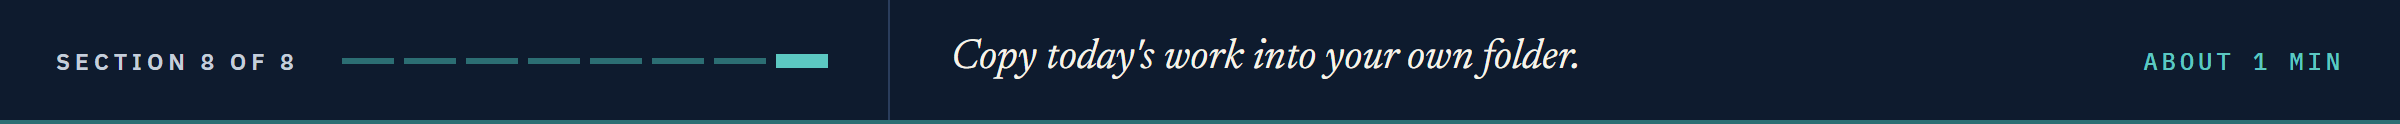

## Bring It Home

Copy today's two files into your own `my_bondmath` folder, then test and commit there.
The copy replaces your files: anything of your own must be in the work folder first.
In PowerShell, with the course's `.venv` active, and your eight characters from the setup cell in place of `k4w7q2xr`:

```powershell
Set-Location "$HOME\projects\my_bondmath"
$work = "$env:TEMP\pfi_course2_14_k4w7q2xr"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py", "$work\.gitignore" .
python -m pytest -q
git diff --stat
git add bondmath.py test_bondmath.py
git status --short
git commit -m "Notebook 14: weighted_average and price_change_estimate" -m "Notebook 14 rolls the bonds up into a book and reprices it under rate and spread what-ifs"
```

If a file slipped in, `git restore --staged <file>` takes it out before the commit.
In Colab, download the two files, and the workbook if you want it, from the work folder in the file browser.
The work folder stays in your temp folder.

## You Can Now

By the end of this notebook, you can:

* Weight a book by market value with `weighted_average`, as Excel's `SUMPRODUCT` over `SUM` does.
* Build a book's risk card from your own functions, and say which numbers are averages and which add up.
* Reprice a whole book in full under parallel shifts and under two shapes of spread move, and say what a scenario is and is not.
* Estimate the same moves with `price_change_estimate`, and say when the shortcut stops being enough.
* Split each scenario's loss by sector, with `groupby` or a PivotTable, and tie the parts back to the book.
* Send a scenario grid as a workbook, and take a file out of the staging area with `git restore --staged`.

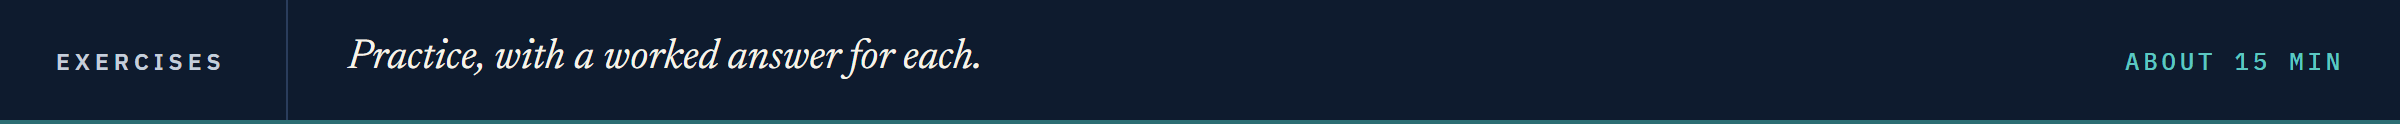

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use notebook 12's twenty bonds from `benchmark.csv`, the ones the book does not hold, with 1,000,000 dollars of face in each.
Replace each `...` with your own code, then run the cell.
Run the next two cells first: `check`, and the twenty bonds as a small book.

In [41]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [42]:
# notebook 12's twenty: every 30th benchmark bond the book does not hold
benchmark = pd.read_csv('benchmark.csv')
not_held = benchmark[~benchmark['cusip'].isin(holdings['cusip'])]
exercise_book = not_held.iloc[::30].head(20).reset_index(drop=True)
exercise_book['as_of_date'] = pd.to_datetime(exercise_book['as_of_date']).dt.date
exercise_book['maturity'] = pd.to_datetime(exercise_book['maturity']).dt.date
# the same face in every bond, in dollars
exercise_book['par_held'] = 1_000_000
exercise_book[['cusip', 'issuer', 'price', 'accrued', 'yield_pct', 'oas']].head()

,cusip,issuer,price,accrued,yield_pct,oas
0,99001BAB2,Quorvane Energy,101.558,0.831,5.524,122
1,99008IAD6,Osmere Chemicals,99.982,1.006,5.252,111
2,99016QAG1,Corvolvey Systems,101.618,0.817,5.075,128
3,99025ZAD7,Kezazor Logistics,98.490,0.150,4.457,71
4,99032GAB4,Queloquil Health,102.218,1.045,6.031,175


### Exercise 1

Q. Set the column `market_value` to each position's face times the file's dirty price (`price` plus `accrued`) over 100, and store the book's value in `ex1_market_value`. Then store the book's duration, from `bondmath.modified_duration` and `bondmath.weighted_average`, in `ex1_duration`.

In [43]:
ex1_market_value = ...
ex1_duration = ...
check('Exercise 1 market value', ex1_market_value, 19891680.0)
check('Exercise 1 book duration', ex1_duration, 5.872304693449307)

Exercise 1 market value: not attempted yet
Exercise 1 book duration: not attempted yet


### Exercise 2

Q. Reprice the twenty in full, as 14.3's `reprice` does, for every yield -100 bp and +100 bp. Store the book's change in dollars in `ex2_down_100` and `ex2_up_100`.

In [44]:
ex2_down_100 = ...
ex2_up_100 = ...
check('Exercise 2 down 100 bp', ex2_down_100, 1227014.845920279)
check('Exercise 2 up 100 bp', ex2_up_100, -1114103.8557471745)

Exercise 2 down 100 bp: not attempted yet
Exercise 2 up 100 bp: not attempted yet


### Exercise 3

Q. Reprice the twenty with every spread up 10 percent and store the change in dollars in `ex3_spread_pnl`. Then store their book DTS, from `bondmath.spread_duration`, `bondmath.dts` and `bondmath.weighted_average`, in `ex3_dts`.

In [45]:
ex3_spread_pnl = ...
ex3_dts = ...
check('Exercise 3 spreads up 10 percent', ex3_spread_pnl, -151874.70737842587)
check('Exercise 3 book DTS', ex3_dts, 768.3161885533202)

Exercise 3 spreads up 10 percent: not attempted yet
Exercise 3 book DTS: not attempted yet


### Exercise 4

Q. Write `scenario_pnl_dollars(par, dirty_price_before, dirty_price_after)`, a position's change in dollars, docstring first, with a test `test_scenario_pnl_dollars_known_case` worked by hand. Append each in its cell below, run the tests with 14.1's cell, and reload. Store the twenty's change for every yield +25 bp, added up from your function, in `ex4_up_25`.

In [46]:
%%writefile -a bondmath.py


# Exercise 4: write scenario_pnl_dollars(par, dirty_price_before, dirty_price_after) below this line

Appending to bondmath.py


In [47]:
%%writefile -a test_bondmath.py


# Exercise 4: write test_scenario_pnl_dollars_known_case() below this line

Appending to test_bondmath.py


In [48]:
ex4_up_25 = ...
check('Exercise 4 up 25 bp', ex4_up_25, -288540.79312331806)

Exercise 4 up 25 bp: not attempted yet


### Exercise 5: AI check

You gave an AI assistant this docstring and asked for the function.
This came back, written for this course in an assistant's style: it runs, and it breaks one convention.

In [49]:
def assistant_market_value_weights_pct(par_held, clean_price, accrued):
    """Market-value weight of each position in the book, in percent.

    Units: par_held in dollars of face; clean_price and accrued per 100 of face. The result is a
    list of percents that sums to 100. Convention: market value = par_held x (clean_price +
    accrued) / 100, on the dirty price, as in the file's market_value. Excel: =R2*(I2+K2)/100
    """
    market_values = []
    for par, price in zip(par_held, clean_price):
        # market value of each position in dollars
        market_values.append(par * price / 100)
    total = sum(market_values)
    return [value / total * 100 for value in market_values]

Q. Test it against the weights from the file's `market_value` column.

In [50]:
weights_pct = assistant_market_value_weights_pct(list(holdings['par_held']),
                                                 list(holdings['price']),
                                                 list(holdings['accrued']))
expected_pct = holdings['market_value'] / total_value * 100
for cusip, weight, expected in zip(holdings['cusip'], weights_pct, expected_pct):
    assert abs(weight - expected) < 1e-9, f'{cusip}: {weight:.6f} percent, the file {expected:.6f}'
print('every weight matches the market_value column')

AssertionError: 99080CAE8: 1.104779 percent, the file 1.107434

Q. Fix the function, run both cells until every weight matches, and store Bezane's weight in `ex5_first_weight` and the book's duration on your weights, `bondmath.weighted_average(list(holdings['duration']), weights_pct)`, in `ex5_book_duration`.

In [51]:
ex5_first_weight = ...
ex5_book_duration = ...
check('Exercise 5 first weight', ex5_first_weight, 1.1074342311557628)
check('Exercise 5 book duration', ex5_book_duration, 6.254777411342789)

Exercise 5 first weight: not attempted yet
Exercise 5 book duration: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">The top lines</td><td align="left">490,819,215.00 dollars; duration 6.2548 years; spread 180.46 bp; DTS 1064.11; convexity 66.99; DV01 306,996.11 dollars per bp</td></tr>
<tr><td align="left">Every yield moved</td><td align="left">-100 bp +32.43 million; -25 bp +7.78; +25 bp -7.57; +100 bp -29.13</td></tr>
<tr><td align="left">Every spread moved</td><td align="left">+25 bp -7.57 million; +10 percent -5.15 million</td></tr>
<tr><td align="left">The shortcut</td><td align="left">within 1,315 dollars at 25 bp; 87,346 at 100 bp</td></tr>
<tr><td align="left">Which sectors</td><td align="left">rate losses follow DV01, proportional spread losses follow DTS</td></tr>
<tr><td align="left">The workbook</td><td align="left"><code>scenario_grid.xlsx</code>, sheets <code>scenarios</code> and <code>by_sector</code></td></tr>
</table>
<br clear="left">

Be proud: a book's risk report, what-ifs included, from functions you wrote and tested.

Next is the Course 2 Capstone: a new book arrives as a raw extract with a cover note, and every tool of the last three weeks gets used.

[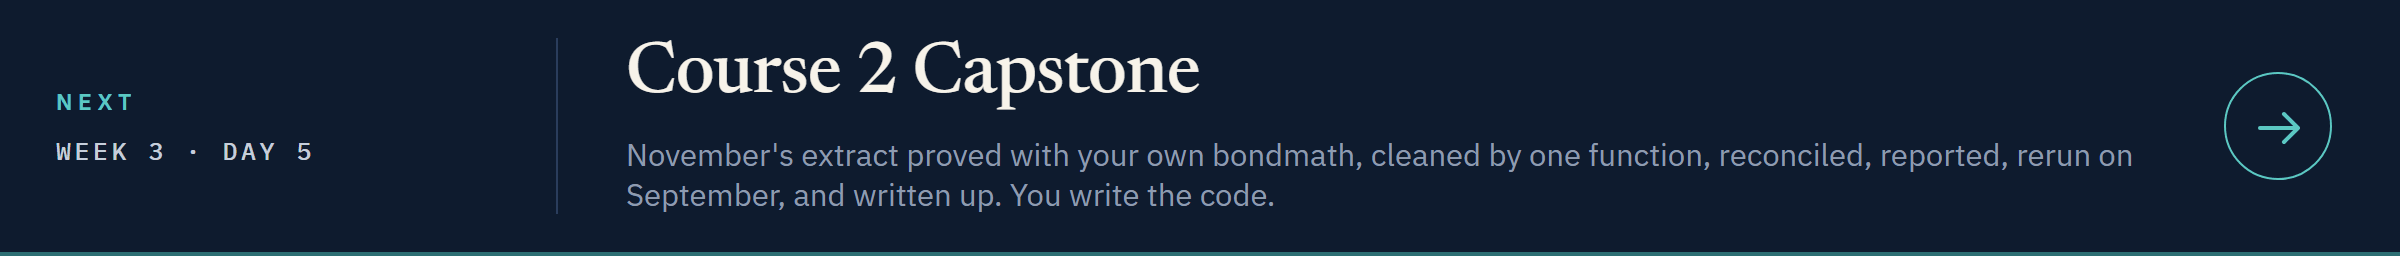](../day5/course2_capstone.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day5/course2_capstone.ipynb)